In [2]:
import pandas as pd
import numpy as np

In [3]:
reg_path= "../../data/logistic_datasets/adtech.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

   clicks  session_time  cart_adds  converted
0      53     13.706722          4          1
1      52     11.564051          5          1
2      54      8.905086          1          1
3      38      4.539688          6          1
4      55      6.350433          3          1


In [4]:
import data_logistic_utils as du

du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['clicks', 'session_time', 'cart_adds', 'converted']

Data Types:
 clicks            int64
session_time    float64
cart_adds         int64
converted         int64
dtype: object

Missing Values:
 clicks          0
session_time    0
cart_adds       0
converted       0
dtype: int64

Statistical Summary:
              clicks  session_time     cart_adds     converted
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      49.921400      9.990713      5.031400      0.993600
std        7.080214      2.994822      2.244798      0.079748
min       27.000000     -1.115450      0.000000      0.000000
25%       45.000000      7.969489      3.000000      1.000000
50%       50.000000      9.976805      5.000000      1.000000
75%       55.000000     12.008379      6.000000      1.000000
max       79.000000     21.298540     15.000000      1.000000


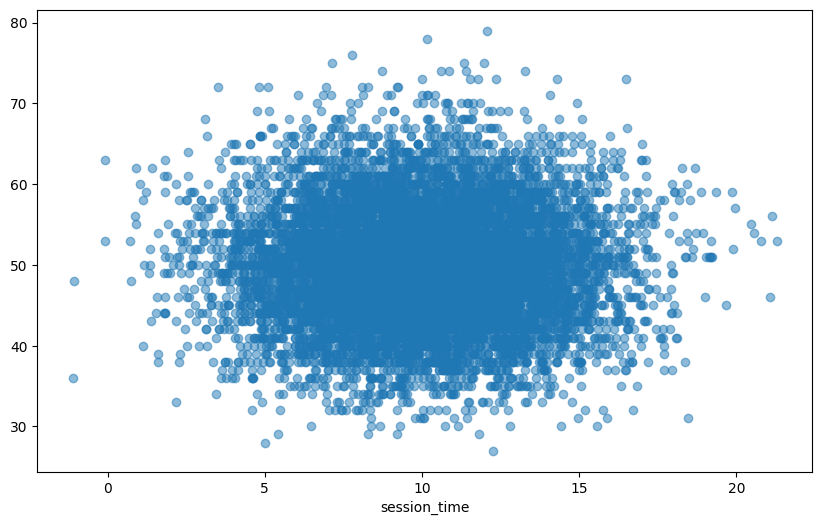

In [5]:
#data visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.scatter(reg_data['session_time'], reg_data['clicks'], alpha=0.5)
plt.xlabel('session_time')
plt.show()

In [6]:
reg_data['converted'].value_counts()

converted
1    9936
0      64
Name: count, dtype: int64

Converted is not spread equally it is more converted only around 99% is 1 only

In [7]:
X = reg_data.drop(columns=['converted'],axis=1)

y = reg_data['converted']

Confusion Matrix:
 [[  12    3]
 [   0 1985]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.80      0.89        15
           1       1.00      1.00      1.00      1985

    accuracy                           1.00      2000
   macro avg       1.00      0.90      0.94      2000
weighted avg       1.00      1.00      1.00      2000



/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encounter

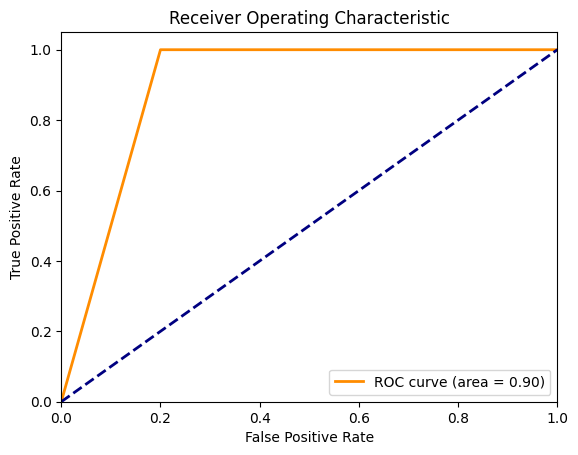

In [8]:
model, y_test, y_pred = du.logitic_regression(X,y)

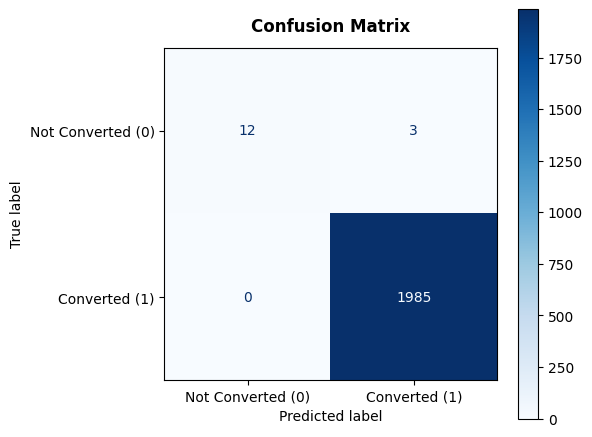

(<Figure size 600x500 with 2 Axes>,
 <Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>)

In [9]:

du.plot_cm(y_test, y_pred, labels=["Not Converted (0)", "Converted (1)"])

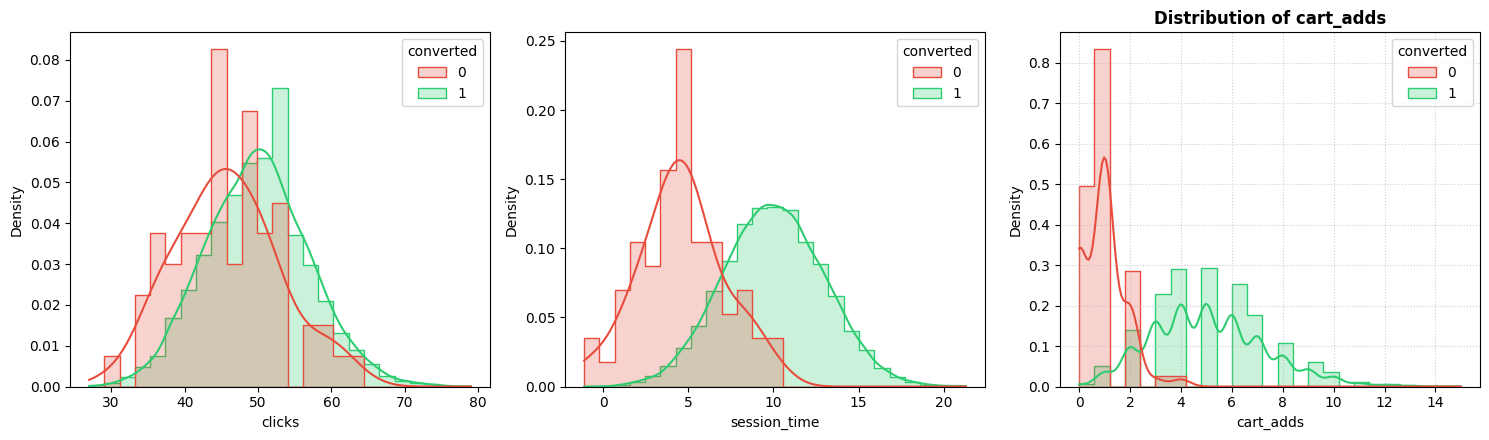

(<Figure size 1500x450 with 3 Axes>,
 array([<Axes: xlabel='clicks', ylabel='Density'>,
        <Axes: xlabel='session_time', ylabel='Density'>,
        <Axes: title={'center': 'Distribution of cart_adds'}, xlabel='cart_adds', ylabel='Density'>],
       dtype=object))

In [11]:
import data_logistic_utils as du
du.plot_hist(reg_data,'converted')